# _Fewer permutations, more accurate p-values_

Here we use the methods of Knijnenberg et al. (2009) to increase the accuracy of the p-value estimation. In brief, a tail is fit to the existing t-statistics, and the p-value is interpolated. This is more accurate than using the naive count. 

Note that this method has been previously implemented in MATLAB(R) in the PALM (Permutation Analysis of Linear Models) toolbox by Winkler et al. Note that our implementation uses the original description by Knijnenberg et al. (2009), not the implementation by Winkler et al.

In [1]:
# Imports
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from neuromodes import mbm as mbm

# Free parameters
n_vertices = 300
n_permutations = 3000
n_subjects = 255
seed = 42
t_synthetic_method = 'repeat' # Options: 'vertex' (independent samples for each vertex) or 'repeat' (one sample repeated for all vertices)

# Fixed parameters for this demonstration
alternative = 'greater'
n_for_pval_reconstruction = 9
n_for_tail_estimation = tuple(range(250, 2, -10))
gof_acceptance_level = 0.05
df = 2 * n_subjects - 2

We start by generating null distributions of t-statistics:

In [2]:
if t_synthetic_method == 'repeat':
    t_random = np.repeat(np.random.default_rng(seed).standard_t(df=df, size=(1, n_permutations)), n_vertices, axis=0)
elif t_synthetic_method == 'vertex':
    t_random = np.random.default_rng(seed).standard_t(df=df, size=(n_vertices, n_permutations))
else:
    raise ValueError("Invalid t_synthetic_method. Choose 'repeat' or 'vertex'.")

Then, for the sake of example, we generate a range of t-statistics spanning a range of p-values: 

In [3]:
# Logarithmically space ground-truth p-values
# Generally GPD fitting is best ~1-2 orders of magnitude below p_naive (1/n_permutations)
p_expected = np.logspace(-np.log10(n_permutations)-1.5, -1, n_vertices)

# Generate observed statistics matching exact theoretical quantiles of the null
t_observed = stats.t.ppf(1 - p_expected, df=df)

We can compute the p-values with and without tail fitting/interpolation: 

In [4]:
p_naive = mbm.mbm_calc_p_vals(
    t_observed, t_random, alternative=alternative, 
    n_for_pval_recalculation=None # turn off the GPD fitting, which otherwise happens by default
)

In [5]:
p_fit = mbm.mbm_calc_p_vals(
    t_observed, t_random, alternative=alternative, 
    n_for_pval_recalculation=n_for_pval_reconstruction,
    n_for_tail_estimation=n_for_tail_estimation, 
    gof_acceptance_level=gof_acceptance_level
)

And can visualise the results (note that the naive p-values that are equal to zero do not appear on the plot): 

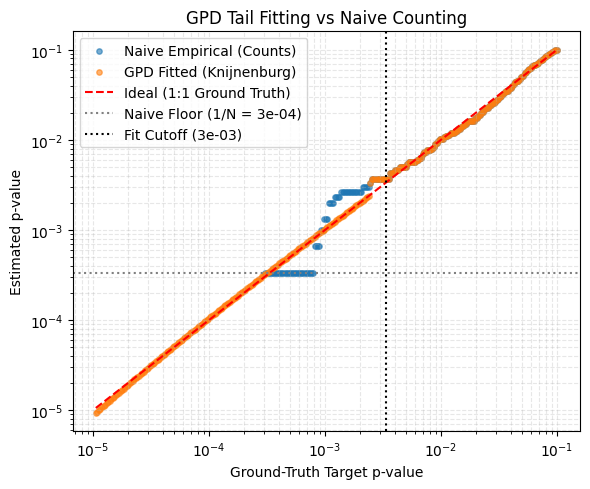

In [6]:
naive_floor = 1 / n_permutations
fit_cutoff = (n_for_pval_reconstruction + 1) / n_permutations

fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(p_expected, p_naive, s=15, alpha=0.6, label='Naive Empirical (Counts)')
ax.scatter(p_expected, p_fit, s=15, alpha=0.6, label='GPD Fitted (Knijnenburg)')
ax.plot(p_expected, p_expected, 'r--', label='Ideal (1:1 Ground Truth)')
ax.axhline(naive_floor, color='gray', linestyle=':', label=f'Naive Floor (1/N = {naive_floor:.0e})')
ax.axvline(fit_cutoff, color='black', linestyle=':', label=f'Fit Cutoff ({fit_cutoff:.0e})')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Ground-Truth Target p-value')
ax.set_ylabel('Estimated p-value')
ax.set_title('GPD Tail Fitting vs Naive Counting')
ax.legend()

plt.grid(True, which="both", ls="--", alpha=0.3)
plt.tight_layout()
plt.show()

> ⚠️ **Check**: The GPD fitted p-values should be closer to the ideal p-values than the naive empirical p-values (the GPD fit should be as close as possible to ideal). 